# 02 — Building a catalog

The catalog is built in two steps.

1. **Base catalog, once.** Every galaxy of the mock with a line above 1.0e-17 erg/s/cm² inside the grism bandpass,
   with its position, redshifts, disk size and the flux of all nine lines. It is written by one batch job:

   ```bash
   sbatch scripts/production.sh          # configs/production.yaml; one CPU node, about 5 minutes
   ```

2. **Catalog, as often as needed.** `base.make_catalog(...)` decides which lines are detected, assigns the
   redshifts with a confusion matrix and selects the sample. It takes a minute or two on a login node.

The detection can be fixed in two ways, and this notebook shows both for the galaxies of every line at 1.5 < z < 1.9:

- **flux limits**: one line above a primary limit, the other lines of such a galaxy above a secondary limit;
- **S/N thresholds**: one line with S/N ≥ 5, the other lines with S/N ≥ 2, the S/N of each line computed from the
  Roman grism sensitivity at its observed wavelength and for the angular size of the galaxy.


In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # diffsky imports JAX; keep it off the GPU

import numpy as np
import matplotlib.pyplot as plt
from romanmock import plotting

plotting.use_style()

MOCK = "sdss_feniks_hizels_260710_09_07_2026"                          # version of the diffsky mock
ROOT = f"/global/cfs/cdirs/m4943/Simulations/RomanMocks/{MOCK}"        # products of romanmock for this mock
CATALOG = f"{ROOT}/catalogs/Every_z1p5_1p9.hdf5"                       # catalog from flux limits (way 1)
CATALOG_SNR = f"{ROOT}/catalogs/Every_z1p5_1p9_snr.hdf5"               # catalog from S/N thresholds (way 2)
AREA_DEG2 = None                                                       # sky area [deg^2] if you know it; None: estimated

## The base catalog

In [2]:
from romanmock import BaseCatalog, Catalog

base = BaseCatalog(f"{ROOT}/base", area_deg2=AREA_DEG2)
print(base)
print(f"sky area: {base.area_deg2:.2f} deg2 ({base.area_source})")

<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_260710_09_07_2026/base: 221,988,100 galaxies in 66 slices, 0.02 < z < 4.00; flux limit 1.00e-17 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312']>
sky area: 2062.65 deg2 (footprint)


## Sky area

`area_deg2` is the sky area of the lightcone, used for every dN/dz. Give it if you know it. With `None` it is
estimated: from the sky patches the mock is made of or, for a mock without a patch decomposition, from the
galaxies. `base.area_source` tells which: `user`, `footprint` or `healpix`.

## Way 1: flux limits

A galaxy is in the catalog when one of its lines inside the bandpass is above the primary flux limit; its other
lines are detected when they are above the secondary limit. One detected line makes a single-line galaxy, several
a multi-line galaxy.

The confusion matrix gives, for a galaxy with a single detected line, the probability that the line is taken
for another one. Lines that are not listed are identified correctly. A galaxy with several detected lines
always gets its correct redshift. The probabilities below are an assumed scenario, not a calibration of
the Roman pipeline: replace them with yours.


In [3]:
confusion = {                                  # {true line: {line it is taken for: probability}}
    "Ha":        {"OIII_5007": 0.3},
    "OIII_5007": {"Ha": 0.3},
    "SIII_9532": {"Ha": 0.3},
    # "Hb":        {"OIII_5007": 0.2},
}

cat = base.make_catalog(
    flux_limit=1.5e-16,               # primary limit [erg/s/cm^2]: one line of the galaxy above it
    secondary_flux_limit=6.0e-17,     # limit for the other lines of such a galaxy (None: no secondary limit)
    confusion=confusion,
    lines=None,                      # galaxies in which every line is identified (["Ha"]: only Ha line)
    z_range=(1.5, 1.9),               # range of the assigned redshift
    columns=["gal_id", "ra", "dec", "redshift_true", "redshift_rsd", "redshift_assigned",
             "id_outcome", "n_det", "line_assigned", "line_bitmask"],
    seed=2026,
    write_to=CATALOG,
)

[romanmock] 66 slices of base, 10 worker(s)


[romanmock] sky area 2062.65 deg2 (estimated from the sky patches of the mock)


[romanmock] 44,929,655 of 221,988,100 base galaxies detected; 8,148,688 in the catalog


[romanmock] lines inside 10000 - 19300 A for redshift_assigned in 1.5 - 1.9 (lightcone: z_rsd 0.01 - 4.06)
  line        rest [A]    redshift      observed [A]       detected   identified    brightest    mistaken  interlopers
  Ha            6564.7  1.500 - 1.900   16412 - 19038     8,148,688    7,976,639    7,976,639     172,049            0
  Hb            4862.8  1.500 - 1.900   12157 - 14102     1,885,808    1,885,808            0           0            0
  OIII_5007     5008.3  1.500 - 1.900   12521 - 14524     7,618,775    7,618,775            0           0      172,049
  OIII_4959     4960.4  1.500 - 1.900   12401 - 14385       831,884      831,884            0           0            0
  OII_3727      3728.6  1.682 - 1.900   10000 - 10813       403,634      403,634            0           0            0
  OIII_4363     4364.3  1.500 - 1.900   10911 - 12656             0            0            0           0            0
  SIII_6312     6313.9  1.500 - 1.900   15785 - 18310       

The report lists the lines inside the bandpass for the redshift cut and the line interlopers: galaxies with a
single detected line that was taken for another line, which puts them at a wrong redshift.

In [4]:
print(cat.summary())

<Catalog: 8,148,688 galaxies, 10 columns ['gal_id', 'ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'n_det', 'line_assigned', 'line_bitmask']; F > 1.50e-16 (other lines > 6.00e-17); redshift_assigned in (1.5, 1.9)>
  MULTI_LINE         7,618,775  ( 93.50%)
  SINGLE_CORRECT       357,864  (  4.39%)
  SINGLE_MISID         172,049  (  2.11%)


In [5]:
from astropy.table import Table

table = Table({name: cat[name][:5] for name in cat.columns})
for name in ("ra", "dec", "redshift_true", "redshift_rsd", "redshift_assigned"):
    table[name].format = ".5f"
table

gal_id,ra,dec,redshift_true,redshift_rsd,redshift_assigned,id_outcome,n_det,line_assigned,line_bitmask
int64,float64,float64,float32,float64,float64,int8,uint8,int8,uint32
108501738,89.29248,63.53752,1.88277,1.88426,1.88426,1,2,0,5
108501963,89.78211,63.69940,1.89754,1.89778,1.89778,1,2,0,5
108501983,89.86461,63.69725,1.89661,1.89816,1.89816,1,2,0,5
108502039,88.00509,63.51933,1.88673,1.88633,1.88633,1,2,0,5
108502042,88.00331,63.54854,1.88792,1.88830,1.88830,1,2,0,5


| column | content |
|---|---|
| `gal_id` | identifier of the galaxy in the diffsky mock, to join any of its other columns |
| `ra`, `dec` | position [degree] |
| `redshift_true` | cosmological redshift |
| `redshift_rsd` | redshift including the peculiar velocity |
| `redshift_assigned` | measured redshift: `redshift_rsd` when the identification is right, displaced for an interloper |
| `id_outcome` | 1 = several lines, 2 = single line identified correctly, 3 = single line misidentified (interloper) |
| `n_det` | number of detected lines |
| `line_assigned` | index of the identified line (the brightest one of a multi-line galaxy); `cat.bit("Ha")` gives the index of a line |
| `line_bitmask` | detected lines, bit `i` = line `i` of `cat.line_names` |

`base.columns` lists every column a catalog can contain, among them the nine line fluxes.


## Way 2: S/N thresholds

`snr` and `secondary_snr` replace the flux limits. The S/N of every line is estimated from the Roman grism
sensitivity of the [WFI technical page](https://science.nasa.gov/mission/roman-space-telescope/wfi-technical/):
the 5σ line-flux limits tabulated against wavelength for a point source and for a galaxy of half-light radius 0.3",
for one hour and twice the minimum zodiacal background. The S/N of a line therefore depends on its flux, its
observed wavelength and the angular size of the galaxy; `exposure_time` [s] and `background` [× minimum zodi]
rescale the noise.

The angular size is either

- a column of the base catalog in proper kpc, `size="r50_disk_2d"` (the half-mass radius of the disk, converted
  with the angular-diameter distance at `redshift_true`; the base catalog carries it since `configs/production.yaml`
  lists it under `base.columns`), or
- one value in arcsec for all galaxies, `size=0.3` (`0.0`: point source).

Everything else — confusion matrix, redshift range, columns, seed — is the same as above. A catalog cannot mix the
two ways: give either the flux limits or the S/N thresholds.


In [6]:
cat_snr = base.make_catalog(
    snr=5.0,                          # one line with S/N >= 5
    secondary_snr=2.0,                # the other lines of such a galaxy with S/N >= 2 (None: no second tier)
    size="r50_disk_2d",               # angular size from the disk radius of each galaxy; or a value in arcsec
    exposure_time=3600.0,             # [s], the WFI reference
    background=2.0,                   # [x minimum zodiacal light], the WFI reference
    confusion=confusion,
    z_range=(1.5, 1.9),
    columns=["gal_id", "ra", "dec", "redshift_true", "redshift_rsd", "redshift_assigned",
             "id_outcome", "n_det", "line_assigned", "line_bitmask", "r50_disk_2d"],
    seed=2026,
    write_to=CATALOG_SNR,
)
print(cat_snr.summary())


[romanmock] 66 slices of base, 10 worker(s)


[romanmock] sky area 2062.65 deg2 (estimated from the sky patches of the mock)


[romanmock] 46,917,362 of 221,988,100 base galaxies detected; 10,120,888 in the catalog


[romanmock] lines inside 10000 - 19300 A for redshift_assigned in 1.5 - 1.9 (lightcone: z_rsd 0.01 - 4.06)
  line        rest [A]    redshift      observed [A]       detected   identified    brightest    mistaken  interlopers
  Ha            6564.7  1.500 - 1.900   16412 - 19038    10,120,883    9,368,417    9,314,424     752,466            5
  Hb            4862.8  1.500 - 1.900   12157 - 14102     3,340,255    3,340,255            0           0            0
  OIII_5007     5008.3  1.500 - 1.900   12521 - 14524     9,037,448    9,037,443       53,993           5      752,466
  OIII_4959     4960.4  1.500 - 1.900   12401 - 14385     1,962,830    1,962,830            0           0            0
  OII_3727      3728.6  1.682 - 1.900   10000 - 10813       164,785      164,785            0           0            0
  OIII_4363     4364.3  1.500 - 1.900   10911 - 12656             0            0            0           0            0
  SIII_6312     6313.9  1.500 - 1.900   15785 - 18310       

<Catalog: 10,120,888 galaxies, 11 columns ['gal_id', 'ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'n_det', 'line_assigned', 'line_bitmask', 'r50_disk_2d']; S/N >= 5 (other lines S/N >= 2), size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x min zodi; redshift_assigned in (1.5, 1.9)>
  MULTI_LINE         9,037,443  ( 89.29%)
  SINGLE_CORRECT       330,974  (  3.27%)
  SINGLE_MISID         752,471  (  7.43%)


The sensitivity model is stored with the catalog. `flux_limit` and `secondary_flux_limit` are then the nominal limits
of the model at 1.5 µm for the chosen size, for reference only: the actual threshold of each line follows its wavelength
and the size of its galaxy.

In [7]:
print(cat_snr.settings["sensitivity"])
print(f"nominal limits at 1.5 um: {cat_snr.settings['flux_limit']:.2e} / {cat_snr.settings['secondary_flux_limit']:.2e} erg/s/cm2")


{'type': 'roman_grism', 'snr': 5.0, 'secondary_snr': 2.0, 'size': {'column': 'r50_disk_2d', 'unit': 'kpc', 'redshift_column': 'redshift_true'}, 'exposure_time': 3600.0, 'background': 2.0, 'size_exponent': 0.5, 'wave_range': [10000.0, 19300.0]}
nominal limits at 1.5 um: 8.10e-17 / 3.24e-17 erg/s/cm2


### Fixed size, and the two ways side by side

With a fixed size the S/N route is a wavelength-dependent flux limit: S/N 5 at 0.3" is 8.1e-17 erg/s/cm² at 1.5 µm,
deeper than the 1.5e-16 of way 1, so the sample is larger (S/N 6.5 at 0.3" gives 1.05e-16 at 1.5 µm, the old baseline).
At 1.5 < z < 1.9 most disks of the mock are larger than 0.3" and their lines are noisier, so the catalog built from
`r50_disk_2d` sits between the two. Towards z = 1.9 Hα moves to the red end of the bandpass, where the sensitivity
degrades, and the two S/N catalogs lose galaxies that the flux-limit catalog keeps.


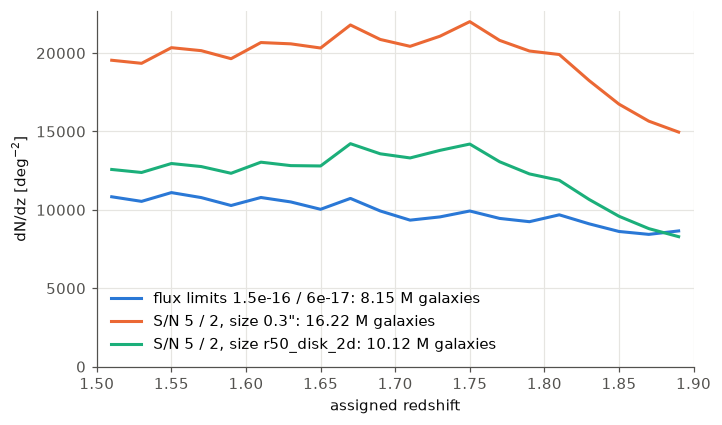

In [8]:
cat_0p3 = base.make_catalog(snr=5.0, secondary_snr=2.0, size=0.3, confusion=confusion, z_range=(1.5, 1.9),
                            columns=["redshift_assigned", "id_outcome"], seed=2026, verbose=False)

z_edges = np.arange(1.5, 1.9 + 1e-6, 0.02)
z_mid = 0.5 * (z_edges[1:] + z_edges[:-1])
samples = [("flux limits 1.5e-16 / 6e-17", cat), ('S/N 5 / 2, size 0.3"', cat_0p3), ("S/N 5 / 2, size r50_disk_2d", cat_snr)]

fig, ax = plt.subplots(figsize=(7, 4.2))
for (label, c), color in zip(samples, plotting.CATEGORICAL):
    ax.plot(z_mid, c.dndz(z_edges), color=color, label=f"{label}: {len(c) / 1e6:.2f} M galaxies")
ax.set(xlabel="assigned redshift", ylabel=r"dN/dz [deg$^{-2}$]", xlim=(1.5, 1.9), ylim=(0, None))
ax.legend(frameon=False)
plt.show()


## Reading it back

In [9]:
cat = Catalog.read(CATALOG)
print(cat)
print(f"sky area: {cat.area_deg2:.2f} deg2 ({cat.info['area_source']})")
print("settings:", {k: cat.settings[k] for k in ("sensitivity", "lines", "z_range", "seed")})

galaxies, interlopers = cat.subset("galaxies"), cat.subset("interlopers")
print(f"{len(galaxies):,} galaxies with a correct redshift, {len(interlopers):,} interlopers "
      f"({100 * len(interlopers) / len(cat):.2f} %)")

<Catalog: 8,148,688 galaxies, 10 columns ['gal_id', 'ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'n_det', 'line_assigned', 'line_bitmask']; F > 1.50e-16 (other lines > 6.00e-17); redshift_assigned in (1.5, 1.9)>
sky area: 2062.65 deg2 (footprint)
settings: {'sensitivity': {'type': 'constant', 'flux_limit': 1.5e-16, 'wave_range': [10000.0, 19300.0], 'secondary_flux_limit': 6e-17}, 'lines': None, 'z_range': [1.5, 1.9], 'seed': 2026}


7,976,639 galaxies with a correct redshift, 172,049 interlopers (2.11 %)


The file is plain HDF5, one dataset per column, and can also be read with `h5py`. The settings of the call
are stored in the file attribute `romanmock_catalog`.

The sky area can also be given per call, `base.make_catalog(..., area_deg2=2062.65)`. It sets `cat.area_deg2`,
the normalisation of `cat.dndz(z_edges)` and of the downsampling to a reference dN/dz. It does not change which
galaxies are selected.

## Other samples

Every argument of `make_catalog` can be changed freely between calls; `help(base.make_catalog)` describes
them all. Two examples:

```python
# [O III] at 2.0 < z < 2.8, on a part of the sky, with the line fluxes
base.make_catalog(lines=["OIII_5007"], z_range=(2.0, 2.8), cuts={"dec": (60.0, 70.0)},
                  columns=["ra", "dec", "redshift_assigned", "id_outcome", "OIII_5007_flux", "Hb_flux"])

# the Halpha sample thinned to the number density forecast by Wang et al. (2022)
base.make_catalog(lines=["Ha"], z_range=(1.0, 1.9), downsample="wang2022")

# S/N thresholds for a deeper survey: point sources, two hours, the lower background of the HLWAS
base.make_catalog(snr=5.0, secondary_snr=2.0, size=0.0, exposure_time=7200.0, background=1.4, z_range=(1.0, 1.9))
```

From the command line:

```bash
romanmock catalog $ROOT/base -o Every_z1p5_1p9.hdf5 --flux-limit 1.5e-16 --secondary-flux-limit 8.0e-17 \
          --confusion confusion.yaml --z-range 1.5 1.9 --seed 2026 --area 2062.65
romanmock catalog $ROOT/base -o Every_z1p5_1p9_snr.hdf5 --snr 5 --secondary-snr 2 --size r50_disk_2d \
          --confusion confusion.yaml --z-range 1.5 1.9 --seed 2026 --area 2062.65
```

In a script, call `make_catalog` below `if __name__ == "__main__":`, because the slices of the base catalog
are read by worker processes.